# 波动率聚集效应

- 数据来源：Binance（ccxt 拉取），日频 OHLCV 缓存于 `data/eth_usdt_1d.csv`
- 时间范围：2021-01-01 ~ 2025-12-31，共 1826 根日线（已验证连续、无缺失）
- 研究目标：验证市场的**波动率聚集效应**（大波动伴随大波动、小波动伴随小波动，即波动率随时间变化且具有持久性）

## 1. 环境与全局参数

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns

# ---- 路径约定：notebook 统一在 notebook/ 目录下运行，数据存于 data/，图片存于 pic/ ----
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "eth_usdt_1d.csv"
PIC_DIR = PROJECT_ROOT / "pic"

RANDOM_STATE = 42  # 全流程随机种子，保证可复现

assert DATA_PATH.exists(), f"数据文件不存在: {DATA_PATH}"
PIC_DIR.mkdir(parents=True, exist_ok=True)

# ---- 绘图风格：中文字体与统一底色 ----
sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "font.family": "Noto Sans CJK SC",
        "axes.unicode_minus": False,
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## 2. 数据加载与校验

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

print(f"行数: {len(df)}")
print(f"时间范围: {df['timestamp'].min():%Y-%m-%d} ~ {df['timestamp'].max():%Y-%m-%d}")
print(f"缺失值总数: {int(df.isna().sum().sum())}")

# 日线连续性检查：加密货币全天候交易，应有完整连续日历日
expected = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="D")
missing = expected.difference(df["timestamp"])
print(f"应有 {len(expected)} 天，实际 {len(df)} 天，缺失 {len(missing)} 天")

df.head()

行数: 1826
时间范围: 2021-01-01 ~ 2025-12-31
缺失值总数: 0
应有 1826 天，实际 1826 天，缺失 0 天


,timestamp,open,high,low,close,volume
0,2021-01-01,737.61,749.11,715.62,728.52,3084.37850
1,2021-01-02,729.46,787.22,715.34,774.56,8325.47357
2,2021-01-03,774.60,1010.82,768.74,978.14,19330.21676
3,2021-01-04,978.03,1160.80,881.58,1042.10,26998.69336
4,2021-01-05,1043.81,1133.80,970.00,1100.22,18624.18143


## 3. 收益率构建与基本统计

波动率聚集关注的是收益率**波动大小**的时间动态，因此先构造收益率序列：
- 简单收益率 `ret = close.pct_change()`
- 对数收益率 `logret = ln(close).diff()`

In [3]:
df["ret"] = df["close"].pct_change()
df["logret"] = np.log(df["close"]).diff()
df["abs_ret"] = df["ret"].abs()

lr = df["logret"].dropna()

stats = {
    "样本量": len(lr),
    "均值": lr.mean(),
    "标准差": lr.std(),
    "年化波动率": lr.std() * np.sqrt(365),
    "偏度": lr.skew(),
    "超额峰度": lr.kurt(),
    "1% 分位": lr.quantile(0.01),
    "99% 分位": lr.quantile(0.99),
    "最差单日": lr.min(),
    "最好单日": lr.max(),
}
pd.Series(stats, name="日对数收益率").to_frame().round(4)

,日对数收益率
样本量,1825.0000
均值,0.0008
标准差,0.0414
年化波动率,0.7905
偏度,-0.2029
超额峰度,5.4553
1% 分位,-0.1172
99% 分位,0.1142
最差单日,-0.3258
最好单日,0.2335


## 4. 可视化

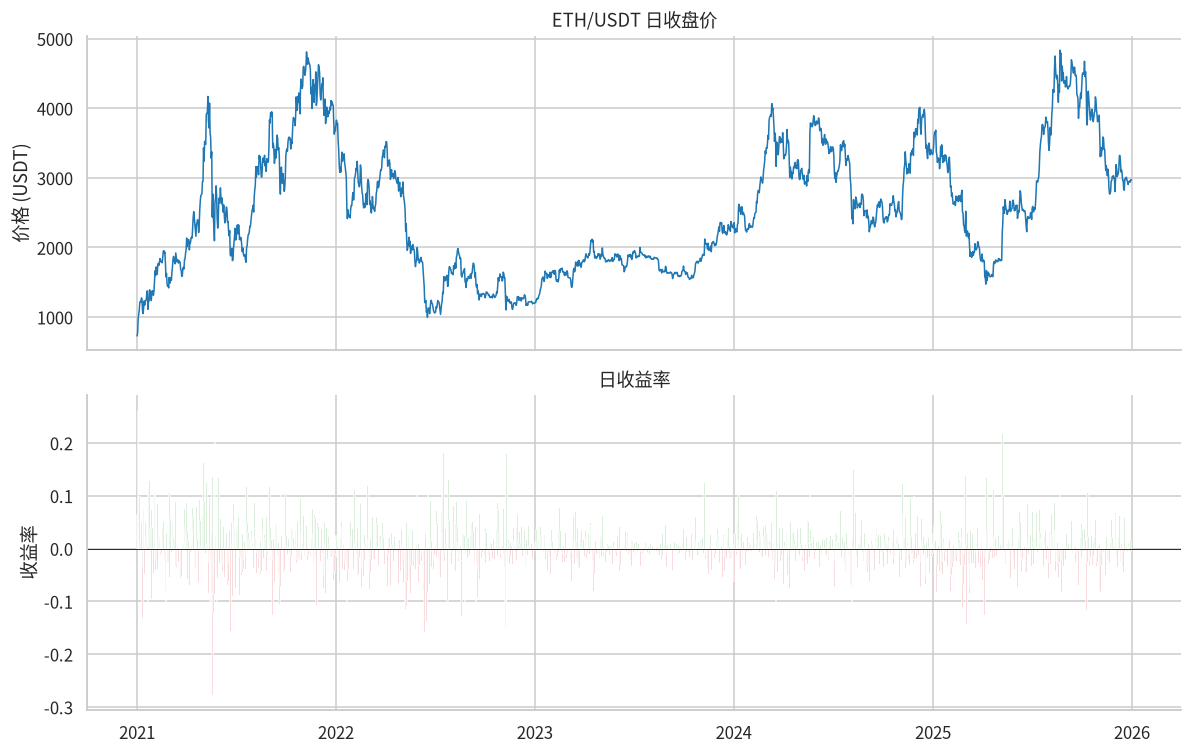

In [4]:
# 图 1：收盘价 + 日收益率时序
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(df["timestamp"], df["close"], lw=1.0, color="#1f77b4")
axes[0].set_title("ETH/USDT 日收盘价")
axes[0].set_ylabel("价格 (USDT)")

bar_colors = np.where(df["ret"] >= 0, "#2ca02c", "#d62728")
axes[1].bar(df["timestamp"], df["ret"], width=1.2, color=bar_colors, alpha=0.8)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_title("日收益率")
axes[1].set_ylabel("收益率")

plt.tight_layout()
plt.show()

t 分布拟合参数: df=2.979, loc=0.0009, scale=0.0263
对数似然 t 分布 : -3395.0
对数似然正态分布: -3223.6


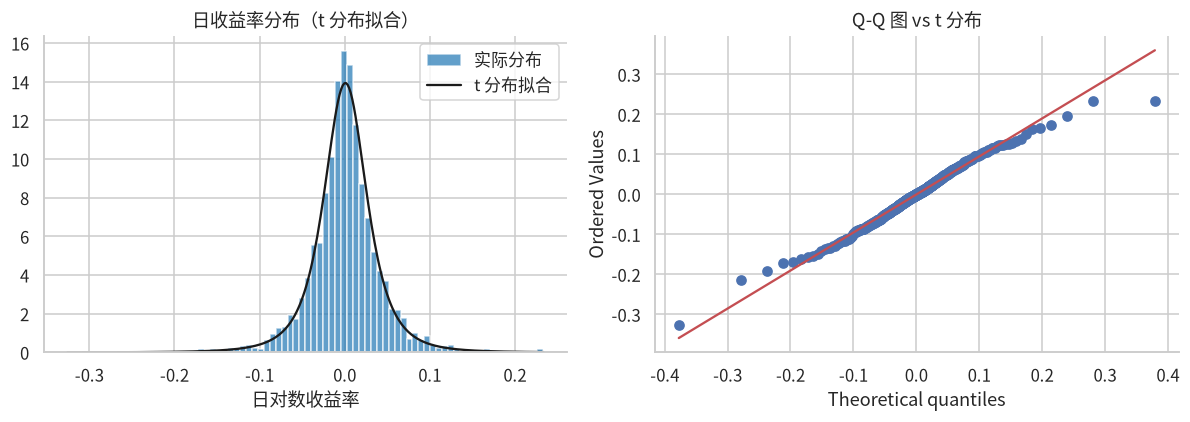

In [5]:
# 图 2：收益率分布 vs t 分布拟合（厚尾检验）
df_t, loc_t, scale_t = st.t.fit(lr)
print(f"t 分布拟合参数: df={df_t:.3f}, loc={loc_t:.4f}, scale={scale_t:.4f}")
print(f"对数似然 t 分布 : {st.t.nnlf((df_t, loc_t, scale_t), lr):.1f}")
print(f"对数似然正态分布: {st.norm.nnlf((lr.mean(), lr.std()), lr):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

x = np.linspace(lr.min(), lr.max(), 300)
axes[0].hist(lr, bins=80, density=True, alpha=0.7, color="#1f77b4", label="实际分布")
axes[0].plot(x, st.t.pdf(x, df_t, loc_t, scale_t), color="k", lw=1.5, label="t 分布拟合")
axes[0].set_title("日收益率分布（t 分布拟合）")
axes[0].set_xlabel("日对数收益率")
axes[0].legend()

st.probplot(lr, dist=st.t, sparams=(df_t, loc_t, scale_t), plot=axes[1])
axes[1].set_title("Q-Q 图 vs t 分布")

plt.tight_layout()
plt.show()

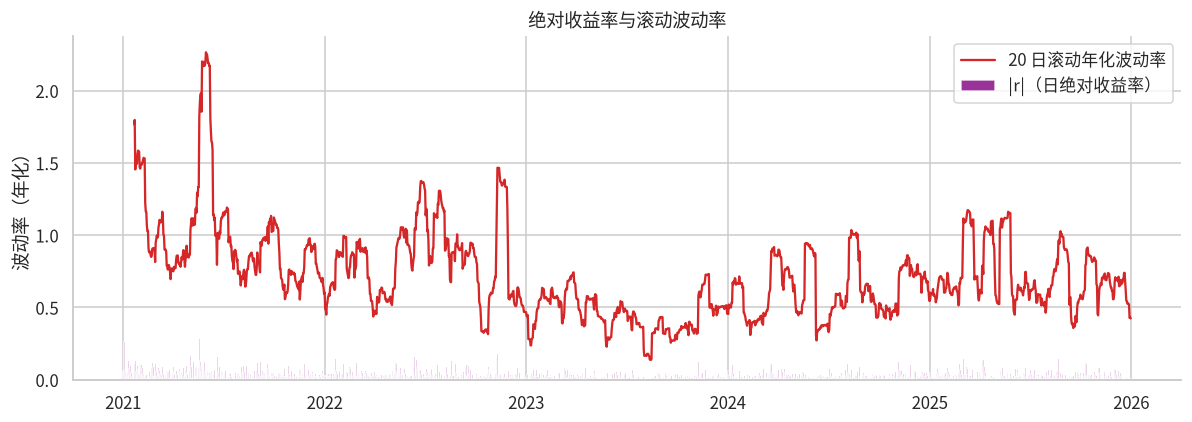

In [6]:
# 图 3：绝对收益率 + 滚动波动率（波动聚集的直观线索）
df["vol20"] = df["ret"].rolling(20).std() * np.sqrt(365)  # 20 日滚动年化波动率

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(df["timestamp"], df["abs_ret"], width=1.2, color="purple", alpha=0.8, label="|r|（日绝对收益率）")
ax.plot(df["timestamp"], df["vol20"], color="#d62728", lw=1.5, label="20 日滚动年化波动率")
ax.set_title("绝对收益率与滚动波动率")
ax.set_ylabel("波动率（年化）")
ax.legend()

plt.tight_layout()
plt.show()

## 5. 假设检验

用三个经典检验量化验证波动率聚集：

| 检验             | 原假设 H₀                | 波动率聚集下的预期                            |
|------------------|--------------------------|-----------------------------------------------|
| 自相关分析 (ACF) | 序列无自相关             | `r` 的 ACF≈0，而 `r²`/`\|r\|` 的 ACF 显著为正 |
| Ljung-Box        | 序列为白噪声             | `r` 无法拒绝，`r²`/`\|r\|` 拒绝               |
| Engle ARCH-LM    | 无异方差（无 ARCH 效应） | 拒绝，即波动率条件异方差                      |

In [7]:
# ---- 自实现统计检验函数 ----

def acf(x, nlags=20):
    """样本自相关函数"""
    x = np.asarray(x, dtype=float)
    n = len(x)
    mu = x.mean()
    denom = ((x - mu) ** 2).sum()
    return np.array(
        [((x[: n - k] - mu) * (x[k:] - mu)).sum() / denom for k in range(nlags + 1)]
    )


def ljung_box(x, lags):
    """Ljung-Box 检验，返回各滞后处的 Q 统计量与 p 值"""
    n = len(x)
    a = acf(x, max(lags))[1:]
    Q = n * (n + 2) * np.cumsum(a**2 / (n - np.arange(1, len(a) + 1)))
    idx = np.array(lags) - 1
    return Q[idx], st.chi2.sf(Q[idx], np.array(lags))


def arch_lm(x, p):
    """Engle ARCH-LM 检验：回归 eps_t^2 于截距及 p 阶滞后，LM = n*R^2 ~ chi2(p)"""
    x = np.asarray(x, dtype=float)
    n = len(x)
    y = x[p:]
    X = np.column_stack([np.ones(n - p)] + [x[p - 1 - j : n - 1 - j] for j in range(p)])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    r2 = 1 - (resid @ resid) / ((y - y.mean()) ** 2).sum()
    lm = (n - p) * r2
    return lm, st.chi2.sf(lm, p), r2

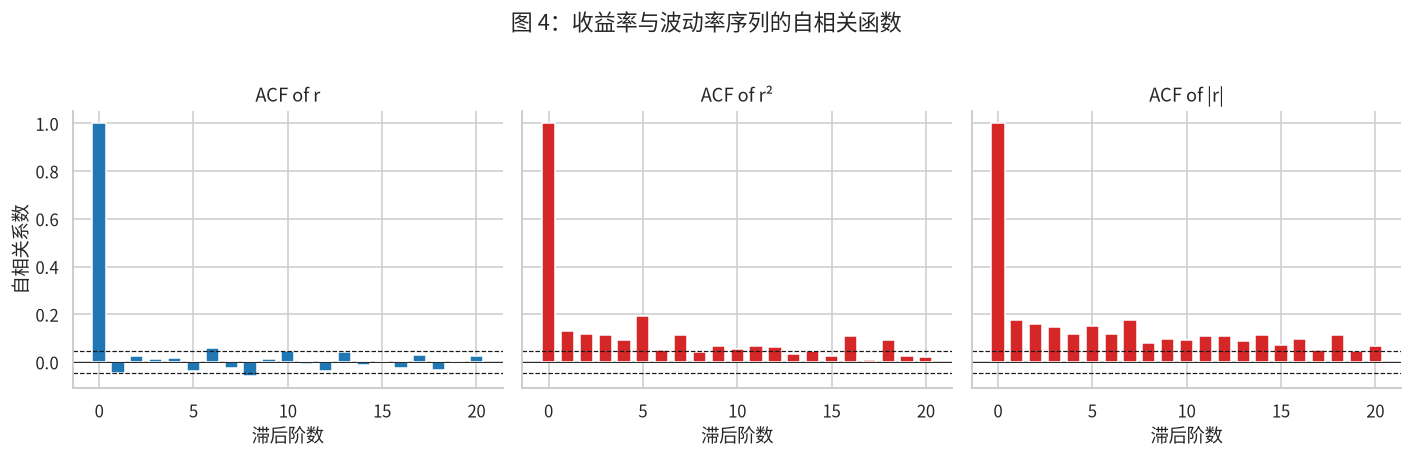

In [8]:
# 图 4：r、r²、|r| 的 ACF 对比（虚线为 ±1.96/sqrt(n) 置信带）
r = df["ret"].dropna()
series = {"r": r, "r²": r**2, "|r|": r.abs()}
nlags = 20
ci = 1.96 / np.sqrt(len(r))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, s) in zip(axes, series.items()):
    a = acf(s, nlags)
    ax.bar(np.arange(nlags + 1), a, width=0.7, color="#1f77b4" if name == "r" else "#d62728")
    ax.axhline(ci, color="k", lw=0.8, ls="--")
    ax.axhline(-ci, color="k", lw=0.8, ls="--")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"ACF of {name}")
    ax.set_xlabel("滞后阶数")
axes[0].set_ylabel("自相关系数")
fig.suptitle("图 4：收益率与波动率序列的自相关函数", y=1.03)
plt.tight_layout()
plt.show()

In [9]:
# ---- Ljung-Box 检验 ----
lags = [1, 5, 10, 20]
rows = []
for name, s in series.items():
    Q, p = ljung_box(s, lags)
    row = {"序列": name}
    row.update({f"Q({k})": round(q, 2) for k, q in zip(lags, Q)})
    row.update({f"p({k})": f"{v:.2e}" for k, v in zip(lags, p)})
    rows.append(row)
lb_df = pd.DataFrame(rows).set_index("序列")
from IPython.display import display
display(lb_df)

Q_r, p_r = ljung_box(r, [10])
Q_r2, p_r2 = ljung_box(r**2, [10])
print(f"结论: r 的 Q(10)={Q_r[0]:.1f}, p={p_r[0]:.3f}（自相关弱，仅长滞后边际显著）；"
      f"r² 的 Q(10)={Q_r2[0]:.1f}, p={p_r2[0]:.2e}（强烈拒绝白噪声）")
print("=> 收益率本身接近白噪声，但波动率序列强自相关，符合波动率聚集特征")

,Q(1),Q(5),Q(10),Q(20),p(1),p(5),p(10),p(20)
序列,,,,,,,,
r,3.83,8.36,26.14,38.59,5.04e-02,1.38e-01,3.56e-03,7.50e-03
r²,31.06,163.55,207.94,271.99,2.50e-08,1.73e-33,3.55e-39,4.08e-46
|r|,55.65,206.51,333.35,479.70,8.65e-14,1.15e-42,1.35e-65,5.13e-89


结论: r 的 Q(10)=26.1, p=0.004（自相关弱，仅长滞后边际显著）；r² 的 Q(10)=207.9, p=3.55e-39（强烈拒绝白噪声）
=> 收益率本身接近白噪声，但波动率序列强自相关，符合波动率聚集特征


In [10]:
# ---- Engle ARCH-LM 检验 ----
r2 = r**2
print(f"{"p":<4}{"LM 统计量":<12}{"p 值":<12}{"R²":<8}检验结论")
for p in [5, 10]:
    lm, pval, R2 = arch_lm(r2, p)
    verdict = "拒绝 H₀（存在 ARCH 效应）" if pval < 0.05 else "无法拒绝 H₀"
    print(f"{p:<4}{lm:<12.2f}{pval:<12.3e}{R2:<8.3f}{verdict}")

lm10, pval10, _ = arch_lm(r2, 10)
print(f"结论: ARCH-LM(10) LM={lm10:.1f}, p={pval10:.2e}，显著拒绝“无异方差”")
print("=> 收益率存在显著的条件异方差（ARCH）效应，即波动率随时间聚集")

p   LM 统计量      p 值         R²      检验结论
5   128.58      4.760e-26   0.071   拒绝 H₀（存在 ARCH 效应）
10  155.47      2.788e-28   0.086   拒绝 H₀（存在 ARCH 效应）
结论: ARCH-LM(10) LM=155.5, p=2.79e-28，显著拒绝“无异方差”
=> 收益率存在显著的条件异方差（ARCH）效应，即波动率随时间聚集
